# 07 — Failure baseline: open-loop vs. closed-loop SBI (Claim 1)

The **headline experiment** for the paper's first claim:

> SBI trained on a **closed-loop** simulator diagnoses faults that the PI controller masks,
> while an SBI trained on an **open-loop** simulator misreads the same observations.

## Experiment design (2026-11-08 run)

| SBI model | Training data | Applied to |
|---|---|---|
| **Closed-loop SBI** (production posterior, nb31) | 160k windows from the 2-D prior [α, β], closed-loop simulator, P1b warm start; 5-seed ensemble | Sc2 (closed-loop data) and Sc6 (open-loop data), both α = 1, β = 0.85 |
| **Open-loop SBI** | 160k windows from the same prior, open-loop simulator (Qc fixed at 80 L/min), 300-min burn-in; single seed | the same observations |

Both use the same 29-D summaries and NSF recipe; the only difference is whether the training
simulator contains the PI controller. Caveat: the closed-loop posterior is a 5-seed ensemble,
the open-loop one a single seed (seed 7).

## What each model should do
- On **Sc2** the controller holds T at its setpoint and absorbs the fouling by raising Qc.
  A model trained without a controller reads fouling through a temperature rise, which is
  absent, and has never seen Qc vary: it should miss or misattribute the fault.
- On **Sc6** (open loop) the roles reverse: the closed-loop model is the misspecified one.

> **2026-11-09 revision — production sensor model N3.** Both posteriors and the data now use the
> realistic sensor model N3 (σ = 0.01 mol/L, 0.2 K, 0.2 K, 2 L/min; notebook 33): the closed-loop
> posterior is the N3 production ensemble from `31_budget_convergence_N3.ipynb`
> (`results/31_N3_production.json`), the open-loop posterior is retrained on the N3 open-loop
> simulator (`results/sbi_posterior_open_p1b_N3_S1_base_est.pkl`), and the observations come from notebook 02
> run under N3. Result files carry the suffix `_N3`. The executed N0 version (commentary of the
> 2026-11-08 run) is archived as `07_failure_baseline_open_vs_closed_N0.ipynb`.
> **N3 run (2026-11-09):** closed-loop posterior = the 40k 5-seed ensemble (rule v2.1), protocol P2, production summary set S1 (32 features); open-loop posterior = 40k simulations (the same budget), single seed (seed 7), the same S1 features; observations from notebook 02 (N3, P2). The design table above and the 2026-11-08 notes describe the earlier N0 run.


> **2026-11-08 revision.** Run after notebook 02 (regenerated P1b data) and nb31 (production
> closed-loop posterior). Sc2/Sc6 have β = 0.85. Execute from `notebooks/system_I`.
> The open-loop posterior is cached after the first run (`RUN_OL_TRAINING = False`; set True to
> retrain, ~18 min). Section 3b measures how much of each posterior lies outside the prior and
> recomputes the metrics on in-prior samples; section 7 interprets the results.

## 1. Setup

In [1]:
from __future__ import annotations
import json, pickle, time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import torch

from cstr_sbi.inference import sample_posterior, train_sbi_posterior
from cstr_sbi.metrics import classify_fault, compute_wasserstein, compute_crps, summarise_posterior
from cstr_sbi.physics import (
    K0_NOMINAL, UA_NOMINAL, NOMINAL_CTRL, NOMINAL_INLET_CL,
    NOMINAL_Y0_CL, CI_NOMINAL,
)
from cstr_sbi.priors import box_uniform_2d
from cstr_sbi.scenarios import SCENARIO_CONFIGS
from cstr_sbi.simulator import (
    simulate_em_window_open_loop, apply_sensor_layer,
    DEFAULT_SENSOR_NOISE_PCT, DEFAULT_PROCESS_SIGMA,
)
from cstr_sbi.summaries import compute_summary_statistics, compute_summary_statistics_batch

jax.config.update("jax_enable_x64", False)

import sys
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT    = NB_DIR.parent.parent
for _p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(_p))
DATA    = ROOT / "data" / "observations.npz"
RESULTS = ROOT / "results"
FIGS    = ROOT / "figures"

# Closed-loop production posterior (2026-11-08: fixed controller law, P1b warm start,
# budget/ensemble chosen by nb31). Replaces the old sbi_posterior_final.pkl.
import os, importlib
os.environ["CSTR_SENSOR_MODEL"] = "N3"   # production sensor model (notebook 33, 2026-11-09)
import system_I_config as CFG, ws_protocols, ws_eval, nb29_ws_study, nb31_budget_convergence
for _m in (CFG, ws_protocols, ws_eval, nb29_ws_study, nb31_budget_convergence):
    importlib.reload(_m)
SENSOR, SFX = CFG.model(), CFG.suffix()
assert SENSOR == "N3", SENSOR
load_production_posterior = nb31_budget_convergence.load_production_posterior
posterior_cl, PROD = load_production_posterior()
print(f"Closed-loop production posterior loaded: protocol {PROD['protocol']}, "
      f"budget {PROD['production_budget']}, {'ensemble' if PROD['use_ensemble'] else 'single seed'}")
_d = np.load(DATA, allow_pickle=False)
assert "protocol" in _d.files and str(_d["protocol"]) == PROD["protocol"], \
    "data/observations.npz is not the regenerated P1b dataset: re-run notebook 02 first"
_data_model = str(_d["sensor_model"]) if "sensor_model" in _d.files else "N0"
assert _data_model == PROD["sensor_model"] == SENSOR, \
    f"sensor model mismatch: data {_data_model}, production posterior {PROD['sensor_model']}, notebook {SENSOR}"
print(f"Sensor model: {CFG.describe()} (data and posterior agree)")

# Load observations
d_obs = np.load(DATA, allow_pickle=False)
x_all     = jnp.asarray(d_obs["x"])    # (400, 120, 4)
t         = jnp.asarray(d_obs["t"])
sid       = d_obs["scenario_id"]
theta_all = d_obs["theta"]

import summary_variants as sv
SET = PROD["summary_set"]            # production summary set (nb03 section 10; N0 S0_base29, N3 S1_base_est)
S_all = np.asarray(ws_eval.features(np.asarray(d_obs["x"]), np.asarray(d_obs["t"]), SET))
print(f"Summaries ({SET}): {S_all.shape}  NaN={np.isnan(S_all).sum()}")
assert S_all.shape[1] == len(sv.SETS[SET]), (S_all.shape, SET)
try:                                  # the closed-loop posterior must accept exactly this feature dimension
    posterior_cl.sample((2,), x=torch.as_tensor(S_all[:1], dtype=torch.float32), show_progress_bars=False)
except Exception as e:
    raise AssertionError(f"feature dimension {S_all.shape[1]} ({SET}) does not match the production posterior: {e}")


Closed-loop production posterior loaded: protocol P2, budget 40000, ensemble
Sensor model: N3: sigma_C=0.01 mol/L, sigma_T=0.2 K, sigma_Tc=0.2 K, sigma_Qc=2.0 L/min (data and posterior agree)
Summaries (S1_base_est): (400, 32)  NaN=0


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2279.)
  outputs, _ = torch.triangular_solve(


## 2. Train open-loop SBI (OL posterior)

Train a second NSF posterior using the **open-loop simulator** (Qc fixed at Qc0=80 L/min).
Same prior, same density estimator, same n_simulations — **only the simulator differs**.
This is the "naive" model that an engineer might deploy without knowing whether
the plant operates in open- or closed-loop mode.


In [2]:
# 2026-11-08: open-loop posterior retrained on the SAME open-loop simulator that generates
# Sc0/Sc6 in notebook 02 (ws_eval.simulate_open_loop: 300-min noisy burn-in at the sampled
# theta before the window), with the production recipe and budget of the closed-loop posterior
# (nb31), so the open- vs closed-loop comparison differs only by the simulator's control mode.
# Previous version: per-draw noise-free open-loop steady state, no burn-in (open-loop P1).
import ws_eval as we
RUN_OL_TRAINING = False   # trained once per sensor model (cached); True retrains (~18 min)
SET = PROD["summary_set"]
OL_PATH = RESULTS / (f"sbi_posterior_open_p1b{SFX}.pkl" if SET == "S0_base29" else f"sbi_posterior_open_p1b{SFX}_{SET}.pkl")
N_OL = int(PROD["production_budget"])

if RUN_OL_TRAINING or not OL_PATH.exists():
    t0 = time.perf_counter()
    theta_ol = we.prior_draws(N_OL, seed=7007)
    x_ol = we.simulate_open_loop(theta_ol, seed=7_007_000, features=SET, **CFG.noise_kw())
    print(f"simulated {x_ol.shape} open-loop training summaries in {time.perf_counter() - t0:.0f}s")
    posterior_ol, meta_ol = we.train_npe(theta_ol, x_ol, seed=7)
    with open(OL_PATH, "wb") as f:
        pickle.dump({"posterior": posterior_ol, "metadata": {**meta_ol, "simulator": "ws_eval.simulate_open_loop",
                                                              "burn_min": 300.0, "sensor_model": SENSOR, "summary_set": SET}}, f)
    print(f"OL training done: {meta_ol}")
else:
    with open(OL_PATH, "rb") as f:
        posterior_ol = pickle.load(f)["posterior"]
    print("Loaded cached OL posterior")
try:                                  # same feature dimension as the closed-loop posterior and the observations
    posterior_ol.sample((2,), x=torch.as_tensor(S_all[:1], dtype=torch.float32), show_progress_bars=False)
except Exception as e:
    raise AssertionError(f"open-loop posterior {OL_PATH.name} does not match the feature set {SET}: {e}")

Loaded cached OL posterior


## 3. Apply both posteriors to Sc2 and Sc6 observations

- **Sc2** (closed-loop, β=0.85): the fault the model was trained to detect; CL SBI should work, OL SBI should struggle.
- **Sc6** (open-loop, β=0.85): observations generated with fixed Qc; OL SBI should be better specified, CL SBI is misspecified.


In [3]:
N_REP = 50  # use all 50 replicates per scenario
N_SAMP = 2_000

results = {}
for sc_id, label in [(2, "Sc2_CL_fouling"), (6, "Sc6_OL_fouling")]:
    mask = np.where(sid == sc_id)[0][:N_REP]
    sc_summaries = S_all[mask]          # (N_REP, d) production summary set
    sc_theta     = theta_all[mask]      # (N_REP, 4)
    beta_true    = float(sc_theta[0, 3])
    alpha_true   = float(sc_theta[0, 2])

    samps_cl, samps_ol = [], []
    for s in sc_summaries:
        samps_cl.append(sample_posterior(posterior_cl, s, n_samples=N_SAMP))
        samps_ol.append(sample_posterior(posterior_ol, s, n_samples=N_SAMP))

    samps_cl = np.stack(samps_cl)   # (N_REP, N_SAMP, 2)
    samps_ol = np.stack(samps_ol)

    results[sc_id] = dict(
        label=label, alpha_true=alpha_true, beta_true=beta_true,
        samps_cl=samps_cl, samps_ol=samps_ol,
    )
    print(f"Sc{sc_id} (β_true={beta_true}):")
    print(f"  CL SBI:  β_mean={samps_cl[:,:,1].mean():.3f}  "
          f"β_cov90={np.mean([np.percentile(samps_cl[i,:,1],5)<=beta_true<=np.percentile(samps_cl[i,:,1],95) for i in range(N_REP)]):.2f}  "
          f"fault_acc={np.mean([classify_fault(samps_cl[i])['class']=='fouling_dominant' for i in range(N_REP)]):.2f}")
    print(f"  OL SBI:  β_mean={samps_ol[:,:,1].mean():.3f}  "
          f"β_cov90={np.mean([np.percentile(samps_ol[i,:,1],5)<=beta_true<=np.percentile(samps_ol[i,:,1],95) for i in range(N_REP)]):.2f}  "
          f"fault_acc={np.mean([classify_fault(samps_ol[i])['class']=='fouling_dominant' for i in range(N_REP)]):.2f}")


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/src/cstr_sbi/inference.py:694: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples = posterior.sample(


Sc2 (β_true=0.8500000238418579):
  CL SBI:  β_mean=0.848  β_cov90=0.94  fault_acc=0.98
  OL SBI:  β_mean=0.769  β_cov90=0.00  fault_acc=0.64


Sc6 (β_true=0.8500000238418579):
  CL SBI:  β_mean=0.876  β_cov90=0.36  fault_acc=0.98
  OL SBI:  β_mean=0.852  β_cov90=0.88  fault_acc=0.98


## 3b. How much of each posterior lies outside the prior? (added 2026-11-08)
Both models are applied to data from the *other* simulator in one of the two scenarios, i.e. to
summaries outside their training distribution (for the open-loop model, any Qc variation at all:
Qc is constant in its training data). Out-of-support samples are the signature of that
extrapolation.

In [4]:
import pandas as pd
# Section 3b -- sample_posterior draws WITHOUT restricting to the prior box (reject_outside_prior=False);
# a warning above reported that for at least one (posterior, scenario) pair all samples fall outside it.
# Measure that, and recompute the beta metrics on the in-prior samples only.
from cstr_sbi.priors import ALPHA_LOW, ALPHA_HIGH, BETA_LOW, BETA_HIGH
LO, HI = np.array([ALPHA_LOW, BETA_LOW]), np.array([ALPHA_HIGH, BETA_HIGH])
rows_leak = []
for sc_id in [2, 6]:
    r = results[sc_id]
    for samps, model in [(r["samps_cl"], "CL-SBI"), (r["samps_ol"], "OL-SBI")]:
        inside = np.all((samps >= LO) & (samps <= HI), axis=2)          # (N_REP, N_SAMP)
        cov, acc, bmean = [], [], []
        for i in range(samps.shape[0]):
            v = samps[i][inside[i]]
            if len(v) < 50:
                continue
            lo5, hi95 = np.percentile(v[:, 1], [5, 95])
            cov.append(lo5 <= r["beta_true"] <= hi95)
            acc.append(classify_fault(v)["class"] == "fouling_dominant")
            bmean.append(v[:, 1].mean())
        rows_leak.append(dict(
            scenario=f"Sc{sc_id}", model=model, frac_outside_prior=float(1 - inside.mean()),
            alpha_mean_raw=float(samps[:, :, 0].mean()), beta_mean_raw=float(samps[:, :, 1].mean()),
            n_windows_with_50_inside=len(cov),
            beta_mean_inprior=float(np.mean(bmean)) if bmean else np.nan,
            beta_cov90_inprior=float(np.mean(cov)) if cov else np.nan,
            fault_acc_inprior=float(np.mean(acc)) if acc else np.nan,
            class_counts_raw=pd.Series([classify_fault(samps[i])["class"] for i in range(samps.shape[0])]).value_counts().to_dict()))
df_leak = pd.DataFrame(rows_leak)
display(df_leak)
df_leak.to_csv(RESULTS / f"07_cl_vs_ol_prior_leakage{SFX}.csv", index=False)
print("A model whose samples lie largely outside the prior is extrapolating beyond its training data:"
      " its point estimates are not interpretable as inference, only its failure is.")

,scenario,model,frac_outside_prior,alpha_mean_raw,beta_mean_raw,n_windows_with_50_inside,beta_mean_inprior,beta_cov90_inprior,fault_acc_inprior,class_counts_raw
0,Sc2,CL-SBI,0.00075,1.006532,0.848125,50,0.848133,0.94,0.98,"{'fouling_dominant': 49, 'combined': 1}"
1,Sc2,OL-SBI,1.00000,1.422804,0.769314,0,NaN,NaN,NaN,"{'fouling_dominant': 32, 'healthy': 16, 'decay..."
2,Sc6,CL-SBI,0.00084,1.006035,0.876178,50,0.876168,0.36,0.98,"{'fouling_dominant': 49, 'combined': 1}"
3,Sc6,OL-SBI,0.00250,1.013145,0.852232,50,0.852281,0.88,0.98,"{'fouling_dominant': 49, 'combined': 1}"


A model whose samples lie largely outside the prior is extrapolating beyond its training data: its point estimates are not interpretable as inference, only its failure is.


## 4. Head-to-head comparison: β posterior distributions

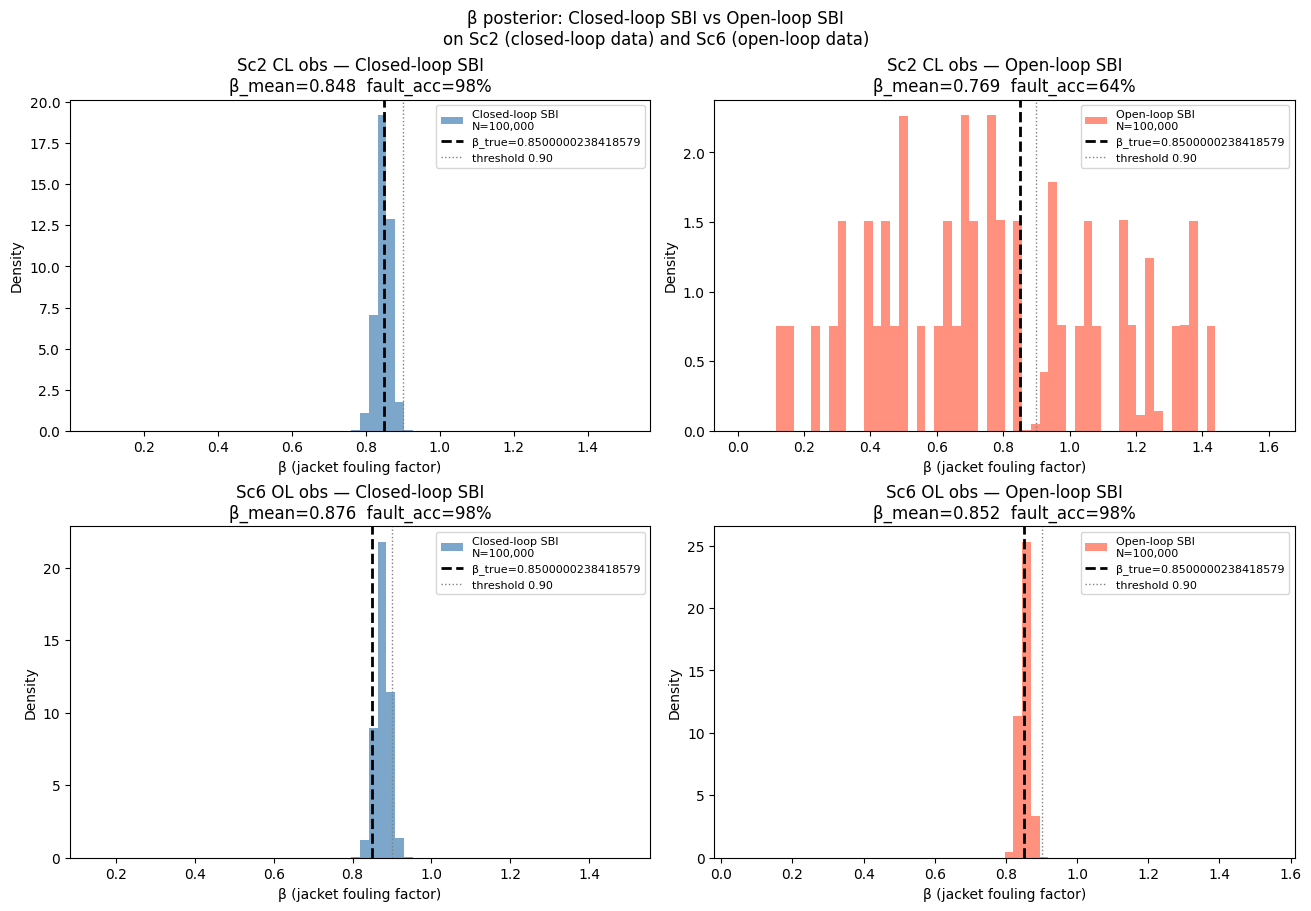

Saved 07_cl_vs_ol_beta_posteriors.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for row, sc_id in enumerate([2, 6]):
    r = results[sc_id]
    beta_true = r['beta_true']

    for col, (samps, label, color) in enumerate([
        (r['samps_cl'], "Closed-loop SBI", "steelblue"),
        (r['samps_ol'], "Open-loop SBI",   "tomato"),
    ]):
        ax = axes[row, col]
        # Pool all replicates for a pooled marginal
        pooled_beta = samps[:, :, 1].ravel()
        ax.hist(pooled_beta, bins=60, density=True, color=color, alpha=0.7,
                label=f"{label}\nN={len(pooled_beta):,}")
        ax.axvline(beta_true, color="k", lw=2, ls="--", label=f"β_true={beta_true}")
        # 0.85 -> 0.90 (2026-08-17, HANDOFF.md TOP PRIORITY / Item 8): tracks
        # classify_fault's recalibrated threshold.
        ax.axvline(0.90, color="gray", lw=1, ls=":", label="threshold 0.90")
        ax.set_xlabel("β (jacket fouling factor)")
        ax.set_ylabel("Density")
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant'
                             for i in range(samps.shape[0])])
        beta_mean = samps[:,:,1].mean()
        ax.set_title(f"{'Sc2 CL obs' if sc_id==2 else 'Sc6 OL obs'} — {label}\n"
                     f"β_mean={beta_mean:.3f}  fault_acc={fault_acc:.0%}")
        ax.legend(fontsize=8)

fig.suptitle("β posterior: Closed-loop SBI vs Open-loop SBI\n"
             "on Sc2 (closed-loop data) and Sc6 (open-loop data)", fontsize=12)
fig.savefig(FIGS / f"07_cl_vs_ol_beta_posteriors{SFX}.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved 07_cl_vs_ol_beta_posteriors.png")

## 5. W1 and CRPS: quantitative comparison

In [6]:
rows_metrics = []
for sc_id in [2, 6]:
    r = results[sc_id]
    beta_true = r['beta_true']
    for samps, model in [(r['samps_cl'], "CL-SBI"), (r['samps_ol'], "OL-SBI")]:
        w1  = np.mean([compute_wasserstein(samps[i,:,1], [beta_true]*N_SAMP) for i in range(N_REP)])
        crps = np.mean([compute_crps(samps[i,:,1], beta_true) for i in range(N_REP)])
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant' for i in range(N_REP)])
        rows_metrics.append(dict(scenario=f"Sc{sc_id}", model=model,
                                 beta_true=beta_true,
                                 beta_mean=float(samps[:,:,1].mean()),
                                 W1_beta=w1, CRPS_beta=crps, fault_acc=fault_acc))

import pandas as pd
df_m = pd.DataFrame(rows_metrics)
print(df_m.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Save
df_m.to_csv(RESULTS / f"07_cl_vs_ol_metrics{SFX}.csv", index=False)
print("\nSaved 07_cl_vs_ol_metrics.csv")


scenario  model  beta_true  beta_mean  W1_beta  CRPS_beta  fault_acc
     Sc2 CL-SBI     0.8500     0.8481   0.0153     0.0076     0.9800
     Sc2 OL-SBI     0.8500     0.7693   0.3042     0.3038     0.6400
     Sc6 CL-SBI     0.8500     0.8762   0.0275     0.0192     0.9800
     Sc6 OL-SBI     0.8500     0.8522   0.0108     0.0053     0.9800

Saved 07_cl_vs_ol_metrics.csv


## 6. α-β joint posteriors (Sc2 CL and Sc6 OL)

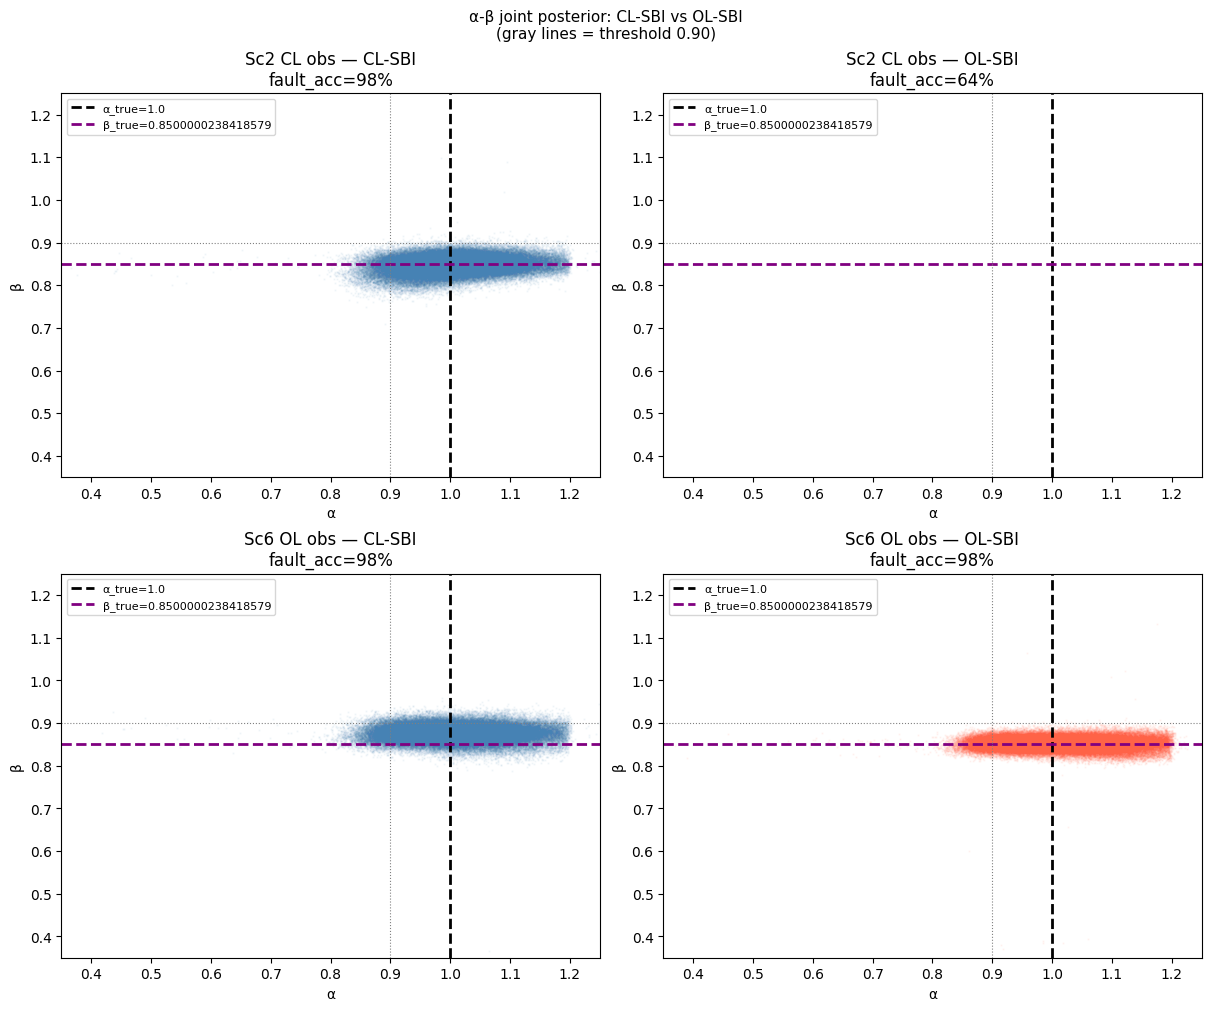

Saved 07_cl_vs_ol_joint.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for row, sc_id in enumerate([2, 6]):
    r = results[sc_id]
    for col, (samps, label, color) in enumerate([
        (r['samps_cl'], "CL-SBI", "steelblue"),
        (r['samps_ol'], "OL-SBI", "tomato"),
    ]):
        ax = axes[row, col]
        pooled = samps.reshape(-1, 2)
        ax.scatter(pooled[:,0], pooled[:,1], s=0.5, alpha=0.05, color=color)
        ax.axvline(r['alpha_true'], color="k", lw=2, ls="--", label=f"α_true={r['alpha_true']}")
        ax.axhline(r['beta_true'],  color="purple", lw=2, ls="--", label=f"β_true={r['beta_true']}")
        # 0.85 -> 0.90 (2026-08-17, HANDOFF.md TOP PRIORITY / Item 8): tracks
        # classify_fault's recalibrated threshold.
        ax.axvline(0.90, color="gray", lw=0.8, ls=":")
        ax.axhline(0.90, color="gray", lw=0.8, ls=":")
        ax.set_xlabel("α"); ax.set_ylabel("β")
        ax.set_xlim(0.35, 1.25); ax.set_ylim(0.35, 1.25)   # the whole prior box [0.4, 1.2]^2
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant' for i in range(N_REP)])
        ax.set_title(f"{'Sc2 CL obs' if sc_id==2 else 'Sc6 OL obs'} — {label}\nfault_acc={fault_acc:.0%}")
        ax.legend(fontsize=8)

fig.suptitle("α-β joint posterior: CL-SBI vs OL-SBI\n(gray lines = threshold 0.90)", fontsize=11)
fig.savefig(FIGS / f"07_cl_vs_ol_joint{SFX}.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved 07_cl_vs_ol_joint.png")

## 7. Results commentary and Claim 1 assessment (N3 run, written 2026-11-09)

**Result.** Claim 1 holds under the production set-up, and the contrast is larger than under N0: the closed-loop posterior recovers the fouling the controller masks (Sc2, β = 0.85: β̂ 0.848, 90% coverage 0.94, class accuracy 0.98), while the open-loop-trained posterior has **no mass inside the prior** on the same observations (100% of its samples outside the prior box, 0 of 50 windows with 50 samples inside) and is 20× worse in Wasserstein distance (W1 0.304 against 0.015). Two N0 patterns do **not** persist in the same form, and I say which (below). Evidence for the motivating application of the paper; tied to the storyline as Claim 1 (closed-loop SBI diagnoses faults the controller masks; a model trained without the controller misreads them) and, through the prior-leakage diagnostic, to the question of how such a failure is detected.

| scenario, model | β̂ (truth 0.85) | β 90% coverage | W1 / CRPS | class accuracy | samples outside the prior |
|---|---|---|---|---|---|
| Sc2 (closed-loop data), **CL-SBI** | 0.848 [N0 0.861] | 0.94 [0.94] | 0.0153 / 0.0076 [0.0285 / 0.0140] | 0.98 [0.96] | 0.08% [0%] |
| Sc2, **OL-SBI** | 0.769 on out-of-support samples [1.008] | 0.00 [0.00] | 0.304 / 0.304 [0.437 / 0.437] | 0.64, not meaningful (see below) [0.28] | **100%** [94%] |
| Sc6 (open-loop data), CL-SBI | 0.876 [0.915] | 0.36 [0.50] | 0.0275 / 0.0192 [0.0717 / 0.0491] | 0.98 [0.38] | 0.08% [0%] |
| Sc6, **OL-SBI** | 0.852 [0.856] | 0.88 [0.94] | 0.0108 / 0.0053 [0.0526 / 0.0247] | 0.98 [0.88] | 0.25% [0.02%] |

(50 windows per scenario; N0 values from the archived notebook in brackets. The closed-loop posterior is an ensemble, the open-loop one a single training run: there is no seed spread for the open-loop model, and the standard error of a coverage fraction over 50 windows is about 0.04–0.07.)

**1. Closed-loop SBI on the masked fault (Sc2): supports claim 1.** The controller holds T at its setpoint and the fouling shows up in Qc; the closed-loop posterior reads it: β̂ 0.848 against a truth of 0.85, coverage 0.94, 98% of the windows classified as fouling-dominant, and a W1 half of the N0 value (0.0153 against 0.0285), as expected from the 2× better β precision under realistic sensors (notebook 33). The posterior stays inside its support (0.08% outside the prior).

**2. Open-loop SBI on the same observations (Sc2): misreads them; the N0 form of the failure does not reproduce.** All of the open-loop posterior's samples lie outside the prior box (N0: 94%), with α̂ = 1.42 on average (the prior ends at 1.2; N0 1.37) and β̂ = 0.77, so no window has 50 in-prior samples and its output is not inference. Under N0 its raw samples put the fouled plant at β̂ ≈ 1.0 (32 of 50 windows "healthy", accuracy 0.28), which was reported as "reads the fouled plant as healthy"; under N3 the raw samples are mostly labelled fouling (32 of 50) with 16 healthy, accuracy 0.64. That figure is computed on samples that lie outside the prior and must not be quoted as a performance: what is robust across the two sensor models is the **out-of-support failure** (94% and 100% of the samples outside the prior, β coverage 0.00, W1 0.30–0.44 against 0.015–0.029 for the closed-loop model), not the direction in which the raw samples happen to fall.

**3. The reversal on the open-loop scenario (Sc6) is partial.** The open-loop model is the better specified one: W1 0.0108 against 0.0275, β coverage 0.88 against 0.36, as under N0. But the class accuracy no longer reverses (both 0.98; N0: 0.88 against 0.38): the closed-loop model stays in its support on open-loop data (0.08% outside the prior) and its β̂ is biased by +0.026 (about two posterior sd, β sd 0.014) with a coverage of 0.36, i.e. it is overconfident and slightly biased, not unusable. With the precise sensors a β error of this size does not cross the 0.90 threshold (0.85 is 3.6 sd below it).

**4. How such a failure is detected (storyline: silent failures).** The prior-leakage diagnostic of section 3b separates the two mismatches: the catastrophic one (open-loop model on closed-loop data, 100% outside the prior) is flagged immediately by the fraction of posterior mass outside the prior, a cheap misspecification check; the mild one (closed-loop model on open-loop data, 0.08% outside, coverage 0.36) is **not** flagged by leakage and is only visible by comparing with the truth, i.e. it is a silent failure in the sense of the paper. A practitioner who deploys a posterior should therefore check the leakage and also the agreement between the modelled and the actual operating mode.

**5. For the paper.** Claim 1 is supported under the production sensor model and holds quantitatively on Sc2 (closed-loop β̂ 0.848, coverage 0.94, accuracy 0.98, against an open-loop posterior with no mass inside the prior). State the N0 difference openly: the specific reading "the open-loop model sees a healthy plant" is not reproduced under N3, and the Sc6 reversal holds for β accuracy and coverage but not for the class accuracy. Limitations: a single open-loop training run, 50 windows per scenario, one β value (0.85); the open-loop posterior's failure at Sc2 is categorical (no mass in the prior) and unlikely to depend on the seed, but that was not tested.
